In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/december-chart-inputs.csv
/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/validation.csv
/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/validation-predictions-template.csv
/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/train-test.csv


In [2]:
val=pd.read_csv("/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/validation-predictions-template.csv")
val

,load_id,predicted_rate
0,TE-000001,NaN
1,TE-000002,NaN
2,TE-000003,NaN
3,TE-000004,NaN
4,TE-000005,NaN
...,...,...
11995,TE-011996,NaN
11996,TE-011997,NaN
11997,TE-011998,NaN
11998,TE-011999,NaN


In [3]:
test=pd.read_csv("/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/december-chart-inputs.csv")
test

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,NaN
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,NaN
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,NaN
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,NaN
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,NaN


In [4]:
temple=pd.read_csv("/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/validation-predictions-template.csv")
temple

,load_id,predicted_rate
0,TE-000001,NaN
1,TE-000002,NaN
2,TE-000003,NaN
3,TE-000004,NaN
4,TE-000005,NaN
...,...,...
11995,TE-011996,NaN
11996,TE-011997,NaN
11997,TE-011998,NaN
11998,TE-011999,NaN


--- فائل کامیابی سے لوڈ ہو چکی ہے! ---

ڈیٹا کا آغاز (Start Date): 2025-01-01 00:00:00
ڈیٹا کا اختتام (End Date): 2025-10-31 00:00:00

--- ماہانہ اوسط ریٹ (Monthly Trend Summary) ---
year_month  posted_rate
   2025-01  2255.967048
   2025-02  2273.804801
   2025-03  2372.268092
   2025-04  2372.162308
   2025-05  2421.776342
   2025-06  2497.030115
   2025-07  2415.162030
   2025-08  2338.407661
   2025-09  2406.374013
   2025-10  2379.051374

----------------------------------------



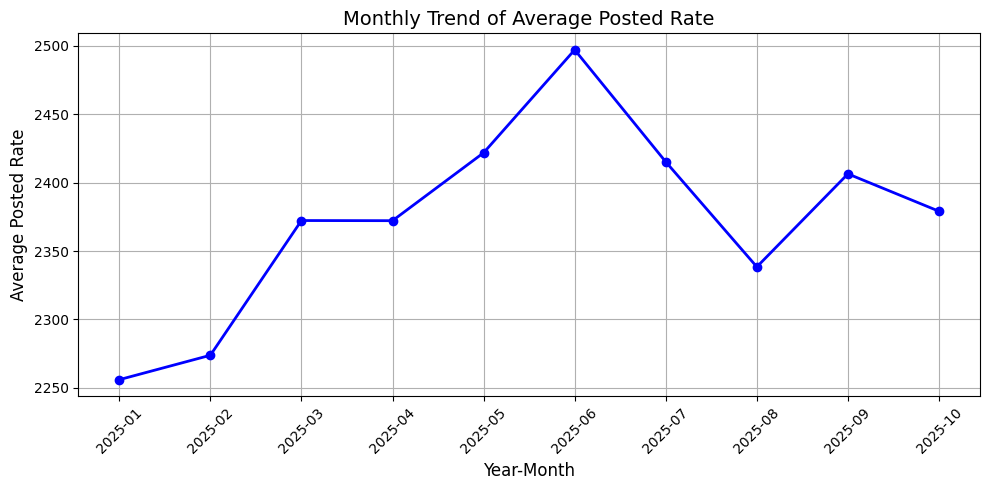

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. کیگل کے پاتھ سے فائل لوڈ کریں
base_path = '/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/'
train_df = pd.read_csv(base_path + 'train-test.csv')

print('--- فائل کامیابی سے لوڈ ہو چکی ہے! ---\n')

# 2. تاریخ کو datetime میں تبدیل کرنا
train_df['date'] = pd.to_datetime(train_df['date'])

# 3. ڈیٹا کا آغاز اور اختتام (Start & End Dates) معلوم کرنا
start_date = train_df['date'].min()
end_date = train_df['date'].max()

print(f'ڈیٹا کا آغاز (Start Date): {start_date}')
print(f'ڈیٹا کا اختتام (End Date): {end_date}\n')

# 4. ماہانہ بنیاد پر ٹارگٹ کالم (posted_rate) کا ٹرینڈ نکالنا
train_df['year_month'] = train_df['date'].dt.to_period('M')
monthly_trend = (
    train_df.groupby('year_month')['posted_rate'].mean().reset_index()
)
monthly_trend['year_month'] = monthly_trend['year_month'].astype(str)

print('--- ماہانہ اوسط ریٹ (Monthly Trend Summary) ---')
print(monthly_trend.to_string(index=False))
print('\n----------------------------------------\n')

# 5. ماہانہ ٹرینڈ کا گراف بنانا (تاکہ اوپر یا نیچے جانے کا واضح پتہ چلے)
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_trend['year_month'],
    monthly_trend['posted_rate'],
    marker='o',
    color='b',
    linestyle='-',
    linewidth=2,
)
plt.title('Monthly Trend of Average Posted Rate', fontsize=14)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Average Posted Rate', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:
train_df

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,year_month
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,2025-01
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,2025-01
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,2025-01
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28,2025-01
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28,2025-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47995,TR-047996,Reno,Baton Rouge,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,2025-10-31,0.98865,2.05626,3787.32,2025-10
47996,TR-047997,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93,2025-10
47997,TR-047998,Greensboro,Cincinnati,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,2025-10-31,1.00846,1.46954,713.36,2025-10
47998,TR-047999,Memphis,Reno,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,2025-10-31,1.00014,2.05132,3987.46,2025-10


--- فائل کامیابی سے لوڈ ہو چکی ہے! ---


/tmp/ipykernel_17/2177644234.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda, x='equipment', y='posted_rate', palette='Set2')


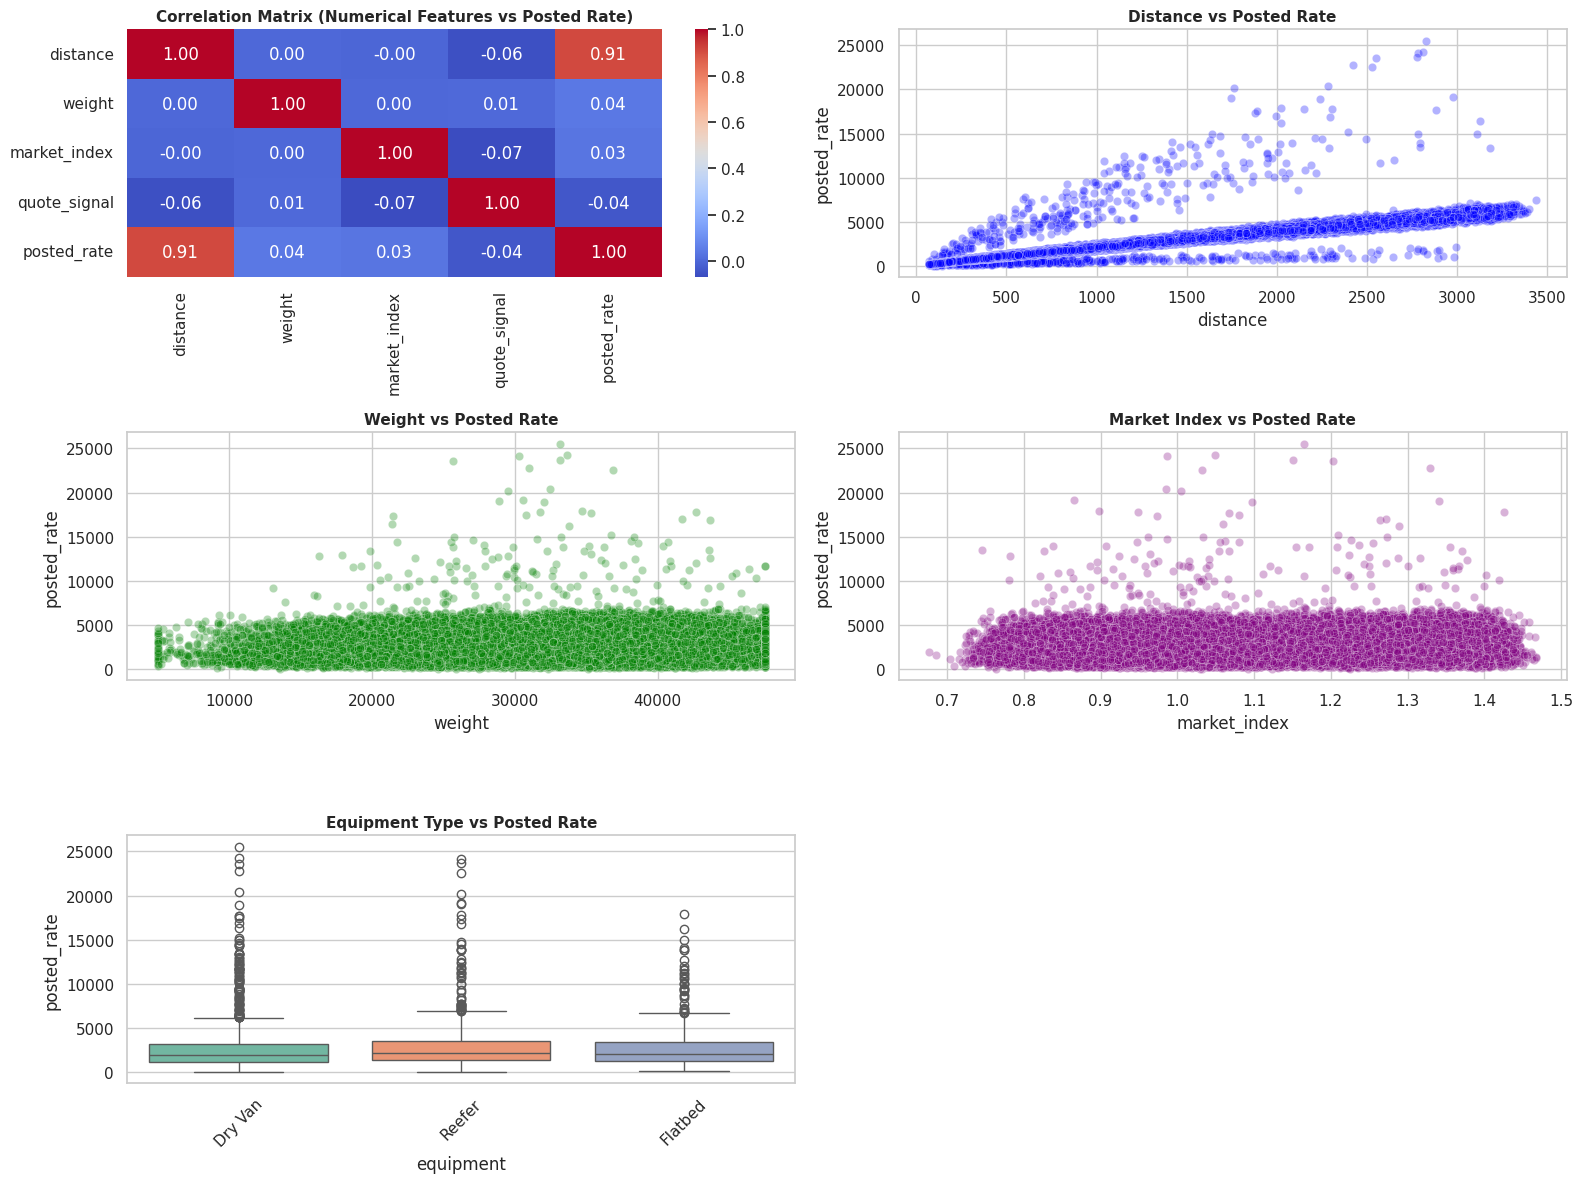

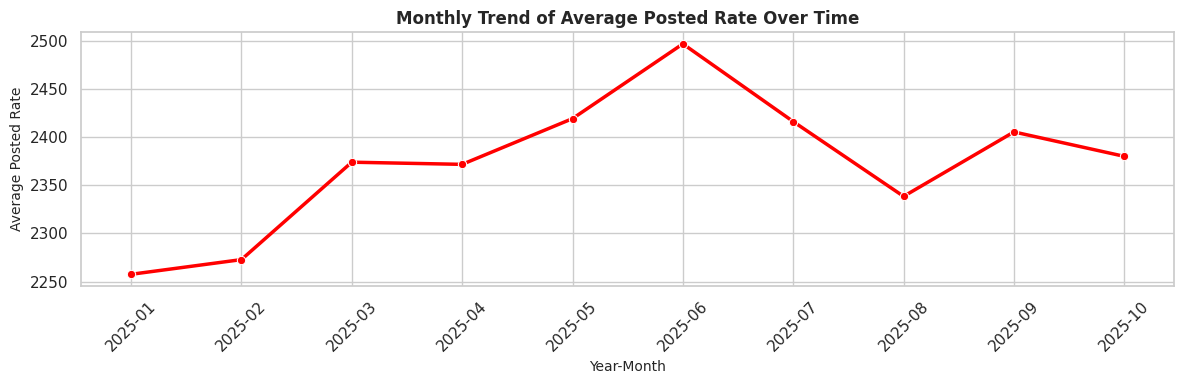

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. کیگل کے پاتھ سے فائل لوڈ کریں

print('--- فائل کامیابی سے لوڈ ہو چکی ہے! ---')

# 2. ڈیٹا کی صفائی (Negative weight ہٹانا)
train_df = train_df[train_df['weight'] > 0].copy()
train_df['date'] = pd.to_datetime(train_df['date'])

# 3. مطلوبہ کالمز کا انتخاب
cols = [
    'distance',
    'equipment',
    'weight',
    'date',
    'market_index',
    'quote_signal',
    'posted_rate',
]
df_eda = train_df[cols].copy()

# گراف کی اسٹائلنگ سیٹ کرنا
sns.set_theme(style='whitegrid')
plt.figure(figsize=(16, 12))

# --- پلاٹ 1: کور ریلیشن ہیٹ میپ (صرف نُمیریکل کالمز کے لیے) ---
plt.subplot(3, 2, 1)
num_df = df_eda.select_dtypes(include=[np.number])
corr = num_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
plt.title(
    'Correlation Matrix (Numerical Features vs Posted Rate)',
    fontsize=11,
    weight='bold',
)

# --- پلاٹ 2: ڈسٹنس اور پوسٹڈ ریٹ کا تعلق (Scatter Plot) ---
plt.subplot(3, 2, 2)
sns.scatterplot(
    data=df_eda, x='distance', y='posted_rate', alpha=0.3, color='blue'
)
plt.title('Distance vs Posted Rate', fontsize=11, weight='bold')

# --- پلاٹ 3: ویٹ اور پوسٹڈ ریٹ کا تعلق (Scatter Plot) ---
plt.subplot(3, 2, 3)
sns.scatterplot(
    data=df_eda, x='weight', y='posted_rate', alpha=0.3, color='green'
)
plt.title('Weight vs Posted Rate', fontsize=11, weight='bold')

# --- پلاٹ 4: مارکیٹ انڈیکس اور پوسٹڈ ریٹ کا تعلق (Scatter Plot) ---
plt.subplot(3, 2, 4)
sns.scatterplot(
    data=df_eda, x='market_index', y='posted_rate', alpha=0.3, color='purple'
)
plt.title('Market Index vs Posted Rate', fontsize=11, weight='bold')

# --- پلاٹ 5: ایکوئپمنٹ کی بنیاد پر پوسٹڈ ریٹ کی تقسیم (Box Plot) ---
plt.subplot(3, 2, 5)
sns.boxplot(data=df_eda, x='equipment', y='posted_rate', palette='Set2')
plt.title('Equipment Type vs Posted Rate', fontsize=11, weight='bold')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# --- پلاٹ 6: وقت کے ساتھ ریٹ کا ٹرینڈ (Line Plot over Time) ---
plt.figure(figsize=(12, 4))
df_eda['year_month'] = df_eda['date'].dt.to_period('M')
monthly_avg = (
    df_eda.groupby('year_month')['posted_rate'].mean().reset_index()
)
monthly_avg['year_month'] = monthly_avg['year_month'].astype(str)

sns.lineplot(
    data=monthly_avg,
    x='year_month',
    y='posted_rate',
    marker='o',
    color='red',
    linewidth=2.5,
)
plt.title(
    'Monthly Trend of Average Posted Rate Over Time',
    fontsize=12,
    weight='bold',
)
plt.xlabel('Year-Month', fontsize=10)
plt.ylabel('Average Posted Rate', fontsize=10)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


--- انڈیکیٹرز کا شماریاتی خلاصہ (Statistical Summary) ---
           distance  market_index  quote_signal        weight   posted_rate
count  47408.000000  47038.000000  47408.000000  47408.000000  47408.000000
mean    1135.887743      1.083445      2.062533  31415.358674   2374.030869
std      728.495026      0.168049      0.291424   7994.902979   1486.103110
min       70.000000      0.676390      0.692280   5000.000000     57.220000
25%      550.475000      0.949830      1.890988  25922.000000   1251.712500
50%      953.400000      1.055890      2.055840  31493.500000   2031.440000
75%     1645.900000      1.219640      2.221742  37063.000000   3330.790000
max     3439.800000      1.467780      3.610350  47500.000000  25533.000000

--- کور ریلیشن میٹرکس (Correlation with Posted Rate) ---
posted_rate     1.000000
distance        0.908552
weight          0.041674
market_index    0.033716
quote_signal   -0.039820
Name: posted_rate, dtype: float64


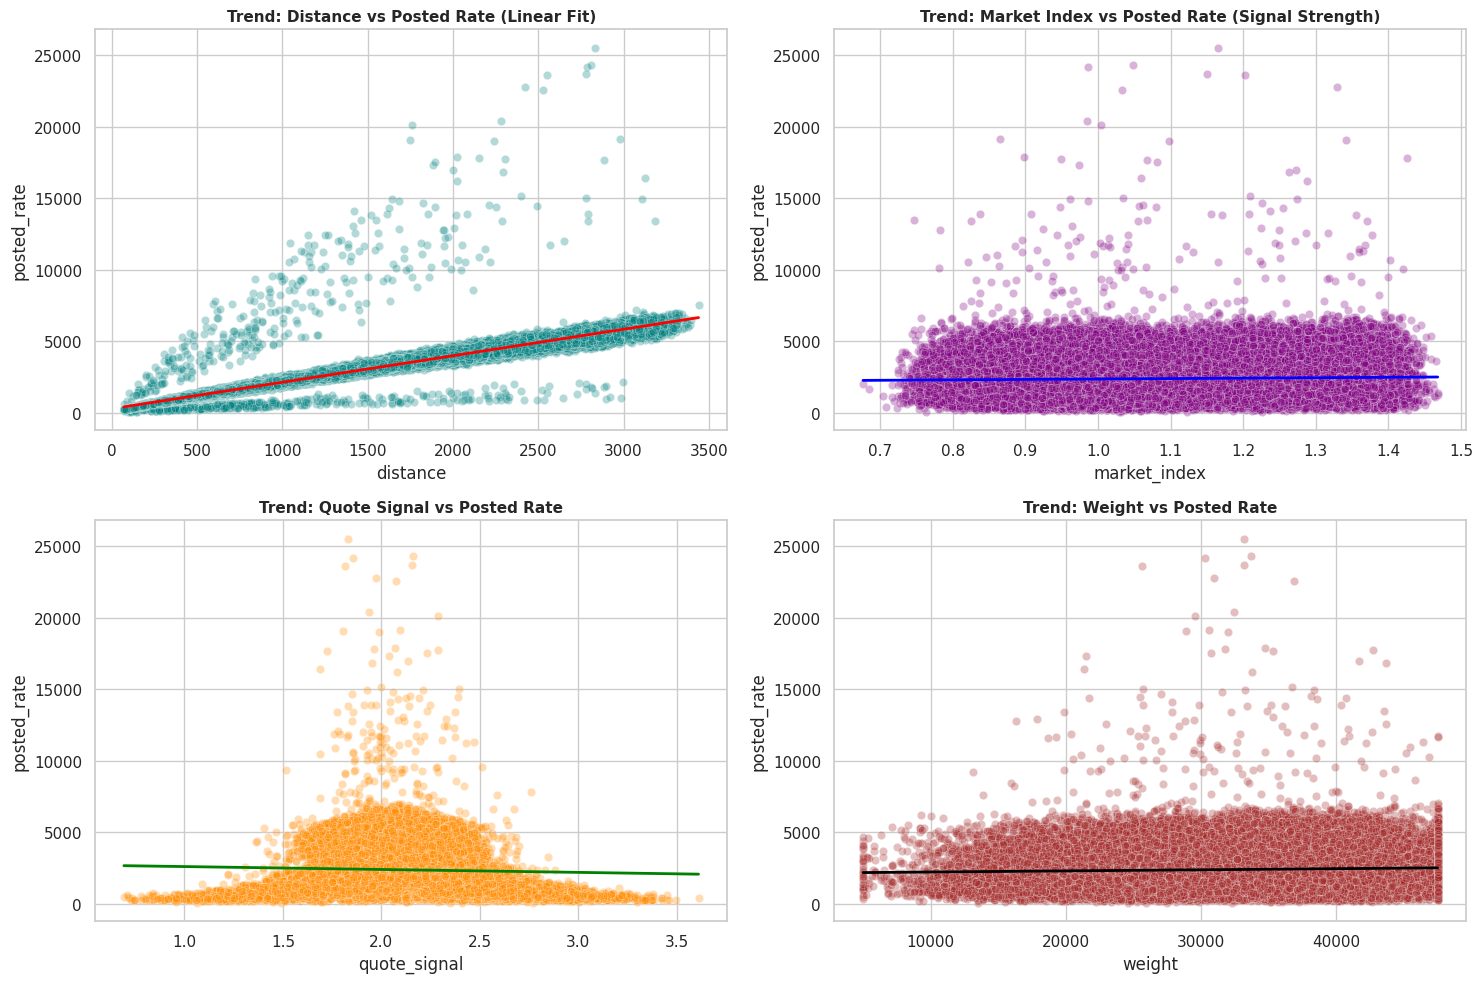

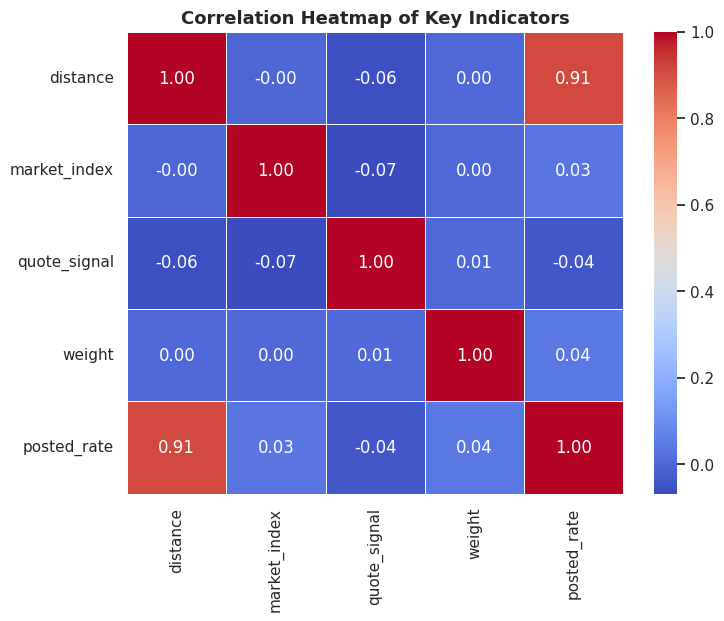

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. کیگل کے پاتھ سے فائل لوڈ کریں

# 2. ڈیٹا کی صفائی (Negative weight ہٹانا)
train_df = train_df[train_df['weight'] > 0].copy()

# 3. تجزیے کے لیے اہم انڈیکیٹرز کا انتخاب
indicators = ['distance', 'market_index', 'quote_signal', 'weight', 'posted_rate']
df_subset = train_df[indicators].copy()

# 4. شماریاتی خلاصہ (Statistical Summary: Mean, Median, Min, Max, Std)
print('\n--- انڈیکیٹرز کا شماریاتی خلاصہ (Statistical Summary) ---')
print(df_subset.describe().to_string())

# 5. کور ریلیشن میٹرکس (Correlation Matrix) - تعلق کا اندازہ لگانے کے لیے
correlation_matrix = df_subset.corr()
print('\n--- کور ریلیشن میٹرکس (Correlation with Posted Rate) ---')
print(correlation_matrix['posted_rate'].sort_values(ascending=False))

# 6. گرافیکل ویژولائزیشن (Trend & Signals)
sns.set_theme(style='whitegrid')
plt.figure(figsize=(15, 10))

# پلاٹ 1: Distance vs Posted Rate (فاصلے کا ریٹ پر اثر)
plt.subplot(2, 2, 1)
sns.scatterplot(
    data=df_subset, x='distance', y='posted_rate', alpha=0.3, color='teal'
)
sns.regplot(
    data=df_subset,
    x='distance',
    y='posted_rate',
    scatter=False,
    color='red',
    line_kws={'linewidth': 2},
)
plt.title(
    'Trend: Distance vs Posted Rate (Linear Fit)', fontsize=11, weight='bold'
)

# پلاٹ 2: Market Index vs Posted Rate (مارکیٹ انڈیکس کا سگنل)
plt.subplot(2, 2, 2)
sns.scatterplot(
    data=df_subset, x='market_index', y='posted_rate', alpha=0.3, color='purple'
)
sns.regplot(
    data=df_subset,
    x='market_index',
    y='posted_rate',
    scatter=False,
    color='blue',
    line_kws={'linewidth': 2},
)
plt.title(
    'Trend: Market Index vs Posted Rate (Signal Strength)',
    fontsize=11,
    weight='bold',
)

# پلاٹ 3: Quote Signal vs Posted Rate (کوٹ سگنل کا ٹرینڈ)
plt.subplot(2, 2, 3)
sns.scatterplot(
    data=df_subset,
    x='quote_signal',
    y='posted_rate',
    alpha=0.3,
    color='darkorange',
)
sns.regplot(
    data=df_subset,
    x='quote_signal',
    y='posted_rate',
    scatter=False,
    color='green',
    line_kws={'linewidth': 2},
)
plt.title(
    'Trend: Quote Signal vs Posted Rate', fontsize=11, weight='bold'
)

# پلاٹ 4: Weight vs Posted Rate (وزن کا اثر)
plt.subplot(2, 2, 4)
sns.scatterplot(
    data=df_subset, x='weight', y='posted_rate', alpha=0.3, color='brown'
)
sns.regplot(
    data=df_subset,
    x='weight',
    y='posted_rate',
    scatter=False,
    color='black',
    line_kws={'linewidth': 2},
)
plt.title('Trend: Weight vs Posted Rate', fontsize=11, weight='bold')

plt.tight_layout()
plt.show()

# 7. کور ریلیشن ہیٹ میپ (Heatmap of all selected indicators)
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title(
    'Correlation Heatmap of Key Indicators', fontsize=13, weight='bold'
)
plt.show()

In [9]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. کیگل کے پاتھ سے فائل لوڈ کریں
base_path = '/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/'
train_df = pd.read_csv(base_path + 'train-test.csv')

print('--- فائل کامیابی سے لوڈ ہو چکی ہے! ---')

# 2. ڈیٹا کی صفائی (Negative weight ہٹانا)
train_df = train_df[train_df['weight'] > 0].copy()

# 3. تاریخ کو datetime میں بدل کر فیچرز بنانا
train_df['date'] = pd.to_datetime(train_df['date'])
train_df['year'] = train_df['date'].dt.year
train_df['month'] = train_df['date'].dt.month
train_df['day'] = train_df['date'].dt.day
train_df['dayofweek'] = train_df['date'].dt.dayofweek
train_df['dayofyear'] = train_df['date'].dt.dayofyear

# مشترکہ نُمیریکل فیچرز کا انتخاب
common_num_features = [
    'distance',
    'weight',
    'year',
    'month',
    'day',
    'dayofweek',
    'dayofyear',
]

# 4. سب سے پہلے ڈیٹا کو اسپلٹ کریں (بغیر کسی تبدیلی کے)
val_months = [3, 9]
val_mask = train_df['month'].isin(val_months)
train_mask = ~val_mask

train_set = train_df[train_mask].copy()
val_set = train_df[val_mask].copy()

print(f'Training Data Rows: {len(train_set)}')
print(f'Validation Data Rows: {len(val_set)}\n')

# 5. اب مسنگ ویلیوز کو صرف ٹریننگ سیٹ کے میڈین سے فل کریں (تاکہ لیکج نہ ہو)
train_median = train_set[common_num_features].median(numeric_only=True)

train_set[common_num_features] = train_set[common_num_features].fillna(
    train_median
)
val_set[common_num_features] = val_set[common_num_features].fillna(
    train_median
)

# 6. TF-IDF ON CATEGORICAL COLUMNS (بغیر ڈیٹا لیکج کے)
train_set['cat_text'] = (
    train_set['pickup'].astype(str)
    + ' '
    + train_set['delivery'].astype(str)
    + ' '
    + train_set['equipment'].astype(str)
)
val_set['cat_text'] = (
    val_set['pickup'].astype(str)
    + ' '
    + val_set['delivery'].astype(str)
    + ' '
    + val_set['equipment'].astype(str)
)

# TF-IDF Vectorizer صرف ٹریننگ ڈیٹا پر فِٹ ہوگا
tfidf = TfidfVectorizer(max_features=500, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(train_set['cat_text'])
X_val_tfidf = tfidf.transform(val_set['cat_text'])

# نُمیریکل فیچرز
X_train_num = train_set[common_num_features].values
X_val_num = val_set[common_num_features].values

# فیچرز کو آپس میں جوڑنا (Horizontal Stack)
X_train_final = sp.hstack([X_train_num, X_train_tfidf])
X_val_final = sp.hstack([X_val_num, X_val_tfidf])

y_train = train_set['posted_rate'].values
y_val = val_set['posted_rate'].values

# ==========================================
# 7. LINEAR REGRESSION ماڈل کی ٹریننگ
# ==========================================
print('--- ماڈل ٹرین ہو رہا ہے ---')
model = LinearRegression()
model.fit(X_train_final, y_train)

# 8. پرڈیکشنز لینا
train_preds = model.predict(X_train_final)
val_preds = model.predict(X_val_final)

# 9. تمام میٹرکس کا حساب اور پرنٹنگ
train_rmse = np.sqrt(mean_squared_error(y_train, train_preds))
train_mae = mean_absolute_error(y_train, train_preds)

val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_mae = mean_absolute_error(y_val, val_preds)

print('\n========================================')
print('  ماڈل کی کارکردگی کے تمام میٹرکس (Metrics)  ')
print('========================================')
print(f'Train RMSE : {train_rmse:.4f}')
print(f'Train MAE  : {train_mae:.4f}')
print('----------------------------------------')
print(f'Val RMSE   : {val_rmse:.4f}')
print(f'Val MAE    : {val_mae:.4f}')
print('========================================')

--- فائل کامیابی سے لوڈ ہو چکی ہے! ---
Training Data Rows: 37837
Validation Data Rows: 9571

--- ماڈل ٹرین ہو رہا ہے ---

  ماڈل کی کارکردگی کے تمام میٹرکس (Metrics)  
Train RMSE : 606.3735
Train MAE  : 153.6189
----------------------------------------
Val RMSE   : 586.8115
Val MAE    : 147.8799


In [10]:
overlap = pd.merge(train_set, val_set, how='inner')
print(f"Duplicate rows across splits: {len(overlap)}")

Duplicate rows across splits: 0


In [11]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression

# 1. پاتھ سیٹ کریں
base_path = '/kaggle/input/datasets/qamarmath/my-asssingmet-first-data-set/'

# 2. ٹریننگ اور ویلیڈیشن/ٹیسٹ فائلیں لوڈ کریں
train_df = pd.read_csv(base_path + 'train-test.csv')
val_data = pd.read_csv(base_path + 'validation.csv')
template_df = pd.read_csv(
    base_path + 'validation-predictions-template.csv'
)

print('--- تمام فائلیں کامیابی سے لوڈ ہو چکی ہیں! ---')

# 3. ڈیٹا کی صفائی (Negative weight ہٹانا)
train_df = train_df[train_df['weight'] > 0].copy()

# 4. تاریخ کو datetime میں بدل کر فیچرز بنانا
for df in [train_df, val_data]:
  df['date'] = pd.to_datetime(df['date'])
  df['year'] = df['date'].dt.year
  df['month'] = df['date'].dt.month
  df['day'] = df['date'].dt.day
  df['dayofweek'] = df['date'].dt.dayofweek
  df['dayofyear'] = df['date'].dt.dayofyear

# مشترکہ نُمیریکل فیچرز
common_num_features = [
    'distance',
    'weight',
    'year',
    'month',
    'day',
    'dayofweek',
    'dayofyear',
]

# 5. مسنگ ویلیوز فل کرنا (بغیر ڈیٹا لیکج کے)
train_median = train_df[common_num_features].median(numeric_only=True)
train_df[common_num_features] = train_df[common_num_features].fillna(
    train_median
)
val_data[common_num_features] = val_data[common_num_features].fillna(
    train_median
)

# 6. TF-IDF فیچرز تیار کرنا
train_df['cat_text'] = (
    train_df['pickup'].astype(str)
    + ' '
    + train_df['delivery'].astype(str)
    + ' '
    + train_df['equipment'].astype(str)
)
val_data['cat_text'] = (
    val_data['pickup'].astype(str)
    + ' '
    + val_data['delivery'].astype(str)
    + ' '
    + val_data['equipment'].astype(str)
)

tfidf = TfidfVectorizer(max_features=500, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(train_df['cat_text'])
X_val_tfidf = tfidf.transform(val_data['cat_text'])

X_train_num = train_df[common_num_features].values
X_val_num = val_data[common_num_features].values

X_train_final = sp.hstack([X_train_num, X_train_tfidf])
X_val_final = sp.hstack([X_val_num, X_val_tfidf])

y_train = train_df['posted_rate'].values

# 7. ماڈل ٹرین کریں
model = LinearRegression()
model.fit(X_train_final, y_train)

# 8. ویلیڈیشن ڈیٹا پر پیشگوئی (Predictions) حاصل کریں
val_predictions = model.predict(X_val_final)
val_data['predicted_rate'] = val_predictions

# 9. ٹیمپلیٹ کے مطابق load_id اور predicted_rate کی فائل تیار کریں
submission_df = template_df[['load_id']].merge(
    val_data[['load_id', 'predicted_rate']], on='load_id', how='left'
)

# اگر کوئی مسنگ پریڈکشن ہو تو میڈین سے فل کریں
submission_df['predicted_rate'] = submission_df['predicted_rate'].fillna(
    y_train.mean()
)

# CSV فائل سیو کریں
submission_df.to_csv('validation_predictions.csv', index=False)
print(
    '--- validation_predictions.csv کامیابی سے تیار اور سیو ہو چکی ہے! ---'
)

--- تمام فائلیں کامیابی سے لوڈ ہو چکی ہیں! ---
--- validation_predictions.csv کامیابی سے تیار اور سیو ہو چکی ہے! ---


In [12]:
submission_df

,load_id,predicted_rate
0,TE-000001,990.423460
1,TE-000002,4927.251829
2,TE-000003,5513.484834
3,TE-000004,4305.733111
4,TE-000005,1913.192507
...,...,...
11995,TE-011996,1026.442640
11996,TE-011997,1645.706122
11997,TE-011998,1203.383186
11998,TE-011999,3558.150586
